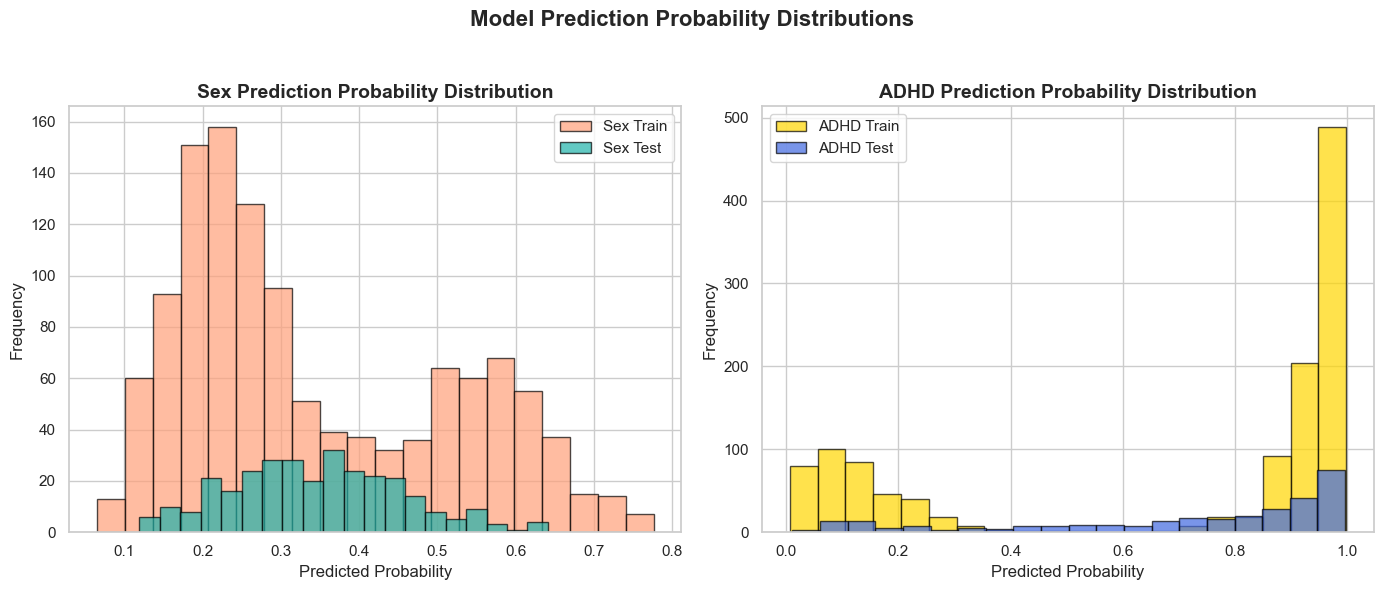

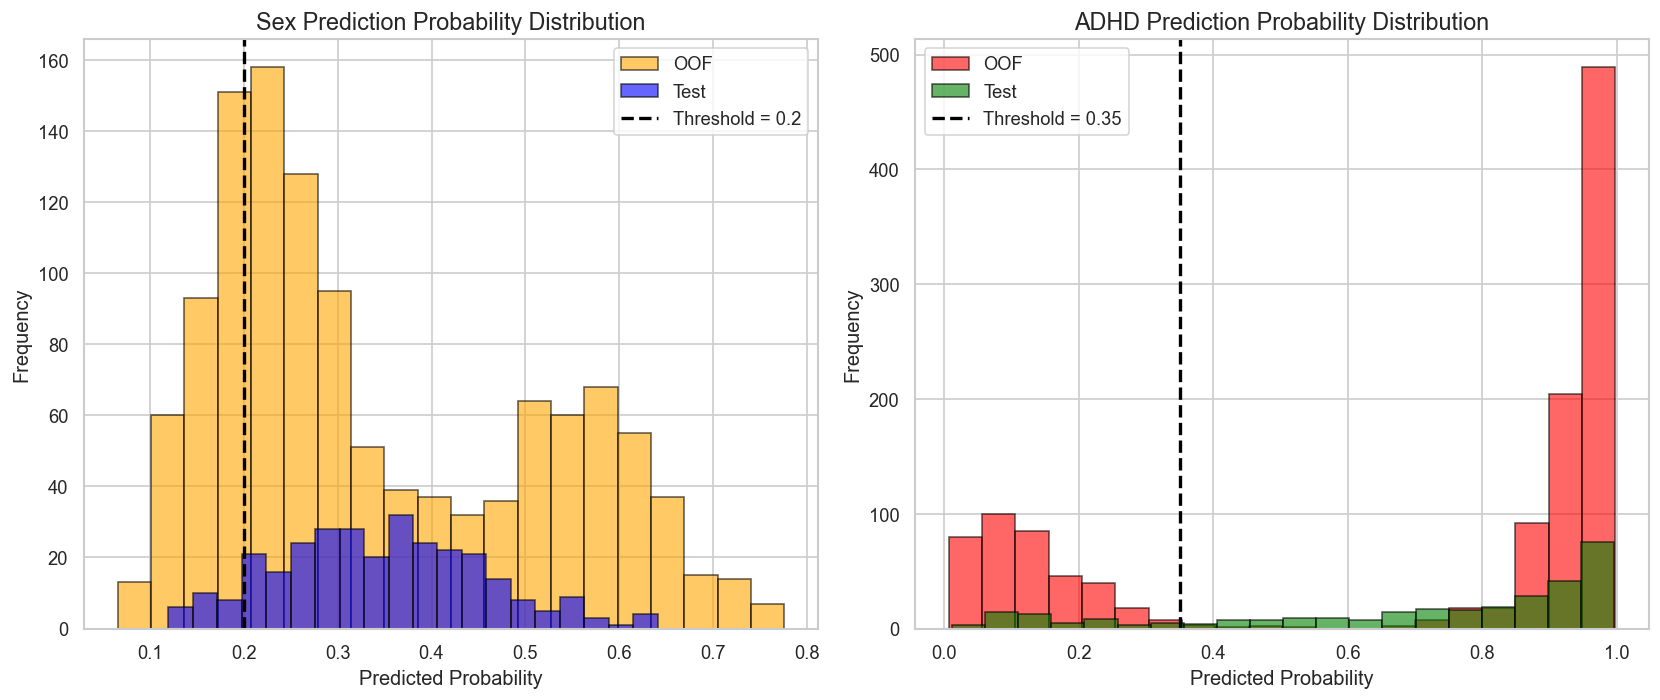

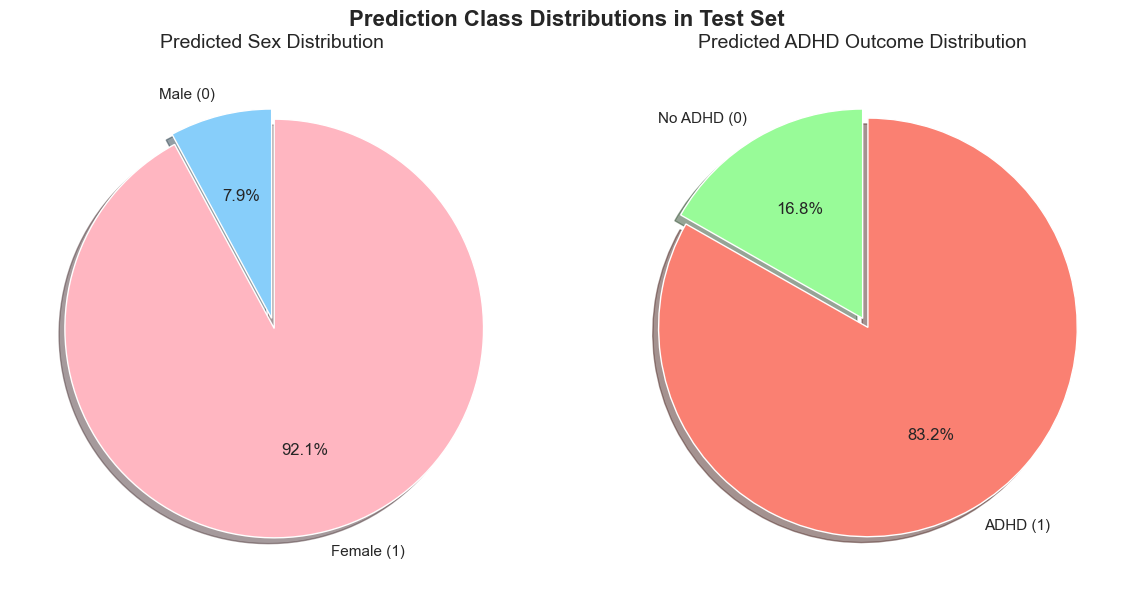

✅ FLAML-optimized submission file created successfully!


In [5]:
# Imports
import pandas as pd
import numpy as np
import re
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from flaml import AutoML
import matplotlib.pyplot as plt
import seaborn as sns

# -----------------------------
# Load data
# -----------------------------
def ensure_participant_id_column(df):
    possible_ids = [col for col in df.columns if 'id' in col.lower()]
    if 'participant_id' in df.columns:
        return df
    elif possible_ids:
        df = df.rename(columns={possible_ids[0]: 'participant_id'})
        return df
    else:
        raise ValueError("No participant ID column found!")

train_cat = ensure_participant_id_column(pd.read_excel(r"D:\\WiDS\\TRAIN_NEW\\TRAIN_CATEGORICAL_METADATA_new.xlsx"))
train_num = pd.read_excel(r"D:\\WiDS\\TRAIN_NEW\\TRAIN_QUANTITATIVE_METADATA_new.xlsx")
train_conn = pd.read_csv(r"D:\\WiDS\\TRAIN_NEW\\TRAIN_FUNCTIONAL_CONNECTOME_MATRICES_new_36P_Pearson.csv")

test_cat = ensure_participant_id_column(pd.read_excel(r"D:\\WiDS\\TEST\\TEST_CATEGORICAL.xlsx"))
test_num = pd.read_excel(r"D:\\WiDS\\TEST\\TEST_QUANTITATIVE_METADATA.xlsx")
test_conn = pd.read_csv(r"D:\\WiDS\\TEST\\TEST_FUNCTIONAL_CONNECTOME_MATRICES.csv")

labels = pd.read_excel(r"D:\\WiDS\\TRAIN_NEW\\TRAINING_SOLUTIONS.xlsx")

# -----------------------------
# Merge datasets
# -----------------------------
combined_cat = pd.concat([train_cat, test_cat], axis=0, ignore_index=True)
combined_num = pd.concat([train_num, test_num], axis=0, ignore_index=True)
combined_conn = pd.concat([train_conn, test_conn], axis=0, ignore_index=True)

# -----------------------------
# Process connectome matrices
# -----------------------------
pattern = r'(\d+)throw_(\d+)thcolumn'
rows, cols, conn_cols = [], [], []

for col in combined_conn.columns:
    if col != 'participant_id':
        match = re.match(pattern, col)
        if match:
            rows.append(int(match.group(1)))
            cols.append(int(match.group(2)))
            conn_cols.append(col)

num_samples = combined_conn.shape[0]
all_matrices = np.zeros((num_samples, 200, 200))
values = combined_conn[conn_cols].values

for idx, (r, c) in enumerate(zip(rows, cols)):
    all_matrices[:, r, c] = values[:, idx]

for i in range(num_samples):
    all_matrices[i] = all_matrices[i] + all_matrices[i].T - np.diag(np.diag(all_matrices[i]))

connection_strengths = all_matrices.sum(axis=1)
connection_means = all_matrices.mean(axis=1)
connection_stds = all_matrices.std(axis=1)

connection_strength_df = pd.DataFrame(connection_strengths, columns=[f"conn_strength_{i}" for i in range(200)])
connection_mean_df = pd.DataFrame(connection_means, columns=[f"conn_mean_{i}" for i in range(200)])
connection_std_df = pd.DataFrame(connection_stds, columns=[f"conn_std_{i}" for i in range(200)])

# Reset index
for df in [connection_strength_df, connection_mean_df, connection_std_df, combined_cat, combined_num]:
    df.reset_index(drop=True, inplace=True)

# -----------------------------
# Label Encoding
# -----------------------------
le = LabelEncoder()
combined_cat["Ethnicity_encoded"] = le.fit_transform(combined_cat["PreInt_Demos_Fam_Child_Ethnicity"].astype(str))
combined_cat["Race_encoded"] = le.fit_transform(combined_cat["PreInt_Demos_Fam_Child_Race"].astype(str))

drop_cols = [
    "participant_id", "Basic_Demos_Enroll_Year", "Basic_Demos_Study_Site",
    "MRI_Track_Scan_Location", "Barratt_Barratt_P1_Edu", "Barratt_Barratt_P1_Occ",
    "Barratt_Barratt_P2_Edu", "Barratt_Barratt_P2_Occ",
    "PreInt_Demos_Fam_Child_Ethnicity", "PreInt_Demos_Fam_Child_Race"
]
combined_cat.drop(columns=drop_cols, errors="ignore", inplace=True)
combined_num.drop(columns=["participant_id"], errors="ignore", inplace=True)

# -----------------------------
# Final feature creation
# -----------------------------
final_features = pd.concat([combined_cat, combined_num, connection_strength_df, connection_mean_df, connection_std_df], axis=1)

train_features = final_features.iloc[:train_num.shape[0], :].copy()
test_features = final_features.iloc[train_num.shape[0]:, :].copy()

# Align labels
labels = labels.set_index('participant_id').loc[train_cat['participant_id'].values].reset_index()

sex_labels = labels['Sex_F']
adhd_labels = labels['ADHD_Outcome']

# -----------------------------
# Sex prediction model
# -----------------------------
SEED = 42
params_sex = {
    'booster': 'dart', 'lambda': 0.01, 'alpha': 0.01, 'subsample': 0.8,
    'colsample_bytree': 0.8, 'n_estimators': 200, 'max_depth': 3,
    'min_child_weight': 3, 'eta': 0.05, 'gamma': 0.01,
    'grow_policy': 'depthwise', 'sample_type': 'weighted',
    'normalize_type': 'forest', 'rate_drop': 0.1, 'skip_drop': 0.1
}
model_sex = XGBClassifier(**params_sex, random_state=SEED, tree_method="hist")
model_sex.fit(train_features, sex_labels)
sex_pred_test = model_sex.predict_proba(test_features)[:, 1]
train_features["sex_pred"] = model_sex.predict_proba(train_features)[:, 1]
test_features["sex_pred"] = sex_pred_test

# -----------------------------
# ADHD model using FLAML
# -----------------------------
automl = AutoML()
automl_settings = {
    "time_budget": 300,  # seconds
    "metric": 'roc_auc',
    "task": 'classification',
    "log_file_name": "flaml_adhd.log",
    "estimator_list": ["xgboost"],
    "verbose": 1,
    "seed": SEED
}

automl.fit(X_train=train_features, y_train=adhd_labels, **automl_settings)
adhd_pred_test = automl.predict_proba(test_features)[:, 1]

##Ploting##

# Set visual style
sns.set(style="whitegrid")

# Define the required variables
sex_proba_test = sex_pred_test
sex_oof = train_features["sex_pred"]
adhd_proba_test = adhd_pred_test
adhd_oof = automl.predict_proba(train_features)[:, 1]

# Create subplots
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

# Sex predictions
ax[0].hist(sex_oof, bins=20, alpha=0.7, label='Sex Train', color='#FFA07A', edgecolor='black')
ax[0].hist(sex_proba_test, bins=20, alpha=0.7, label='Sex Test', color='#20B2AA', edgecolor='black')
ax[0].set_title('Sex Prediction Probability Distribution', fontsize=14, fontweight='bold')
ax[0].set_xlabel('Predicted Probability', fontsize=12)
ax[0].set_ylabel('Frequency', fontsize=12)
ax[0].legend()
ax[0].grid(True)

# ADHD predictions
ax[1].hist(adhd_oof, bins=20, alpha=0.7, label='ADHD Train', color='#FFD700', edgecolor='black')
ax[1].hist(adhd_proba_test, bins=20, alpha=0.7, label='ADHD Test', color='#4169E1', edgecolor='black')
ax[1].set_title('ADHD Prediction Probability Distribution', fontsize=14, fontweight='bold')
ax[1].set_xlabel('Predicted Probability', fontsize=12)
ax[1].set_ylabel('Frequency', fontsize=12)
ax[1].legend()
ax[1].grid(True)

# Overall layout
plt.suptitle("Model Prediction Probability Distributions", fontsize=16, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()



##Threshold ploting 
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp, mannwhitneyu

# Assuming these variables exist
sex_proba_test = sex_pred_test
sex_oof = train_features["sex_pred"]
adhd_proba_test = adhd_pred_test
adhd_oof = automl.predict_proba(train_features)[:, 1]

# Thresholds
t_sex = 0.2
t_adhd = 0.35

# Plotting
fig, ax = plt.subplots(1, 2, figsize=(14, 6), dpi=120)

# --- Sex prediction histogram ---
ax[0].hist(sex_oof, bins=20, alpha=0.6, color='orange', label='OOF', edgecolor='black')
ax[0].hist(sex_proba_test, bins=20, alpha=0.6, color='blue', label='Test', edgecolor='black')
ax[0].axvline(t_sex, color='black', linestyle='--', linewidth=2, label=f'Threshold = {t_sex}')
ax[0].set_title("Sex Prediction Probability Distribution", fontsize=14)
ax[0].set_xlabel("Predicted Probability", fontsize=12)
ax[0].set_ylabel("Frequency", fontsize=12)
ax[0].legend()

# --- ADHD prediction histogram ---
ax[1].hist(adhd_oof, bins=20, alpha=0.6, color='red', label='OOF', edgecolor='black')
ax[1].hist(adhd_proba_test, bins=20, alpha=0.6, color='green', label='Test', edgecolor='black')
ax[1].axvline(t_adhd, color='black', linestyle='--', linewidth=2, label=f'Threshold = {t_adhd}')
ax[1].set_title("ADHD Prediction Probability Distribution", fontsize=14)
ax[1].set_xlabel("Predicted Probability", fontsize=12)
ax[1].set_ylabel("Frequency", fontsize=12)
ax[1].legend()

plt.tight_layout()
plt.show()


# Pie chart for predicted Sex (Sex_F: 1 = Female, 0 = Male)
sex_counts = submission['Sex_F'].value_counts().sort_index()
sex_labels = ['Male (0)', 'Female (1)']
sex_colors = ['#87CEFA', '#FFB6C1']  # light blue and pink

# Pie chart for predicted ADHD (ADHD_Outcome: 1 = ADHD, 0 = Non-ADHD)
adhd_counts = submission['ADHD_Outcome'].value_counts().sort_index()
adhd_labels = ['No ADHD (0)', 'ADHD (1)']
adhd_colors = ['#98FB98', '#FA8072']  # light green and salmon

# Create subplots
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# --- Sex Pie ---
axes[0].pie(sex_counts, labels=sex_labels, colors=sex_colors, autopct='%1.1f%%', startangle=90, explode=(0, 0.05), shadow=True)
axes[0].set_title("Predicted Sex Distribution", fontsize=14)

# --- ADHD Pie ---
axes[1].pie(adhd_counts, labels=adhd_labels, colors=adhd_colors, autopct='%1.1f%%', startangle=90, explode=(0, 0.05), shadow=True)
axes[1].set_title("Predicted ADHD Outcome Distribution", fontsize=14)

plt.suptitle("Prediction Class Distributions in Test Set", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()


    
# -----------------------------
# Submission
# -----------------------------
t_sex = 0.2
t_adhd = 0.35

submission = pd.DataFrame({
    "participant_id": test_cat['participant_id'],
    "Sex_F": (sex_pred_test > t_sex).astype(int),
    "ADHD_Outcome": (adhd_pred_test > t_adhd).astype(int)
})

submission.to_csv("FLAML_XGBOOST_ADHD.csv", index=False)
print("✅ FLAML-optimized submission file created successfully!")
